# Librerías científicas · Cálculo y ciencia

Ejercicios de [El Libro De Python](https://ellibrodepython.com/ejemplos-ejercicios-python) con librerías de cálculo simbólico, geografía, química, simulación e imagen.

## 1. Sistema de ecuaciones con `sympy`

Resolver el sistema $x + 7y = 10$, $3x - 2y = 7$.

In [1]:
import sympy as sp

x, y = sp.symbols("x y")
print(sp.solve([sp.Eq(x + 7 * y, 10), sp.Eq(3 * x - 2 * y, 7)], [x, y]))
p = x**3 + 3 * x + 10
print("Derivada:", sp.diff(p, x), "| Integral:", sp.integrate(p, x))

{x: 3, y: 1}
Derivada: 3*x**2 + 3 | Integral: x**4/4 + 3*x**2/2 + 10*x


## 2. Distancias con distintos elipsoides en `geopy`

`geodesic` calcula por defecto la distancia entre Madrid y Buenos Aires con el elipsoide WGS-84. Comparar con los otros modelos de elipsoide disponibles.

In [2]:
from geopy.distance import ELLIPSOIDS, geodesic, great_circle

madrid, buenos_aires = (40.4168, -3.7038), (-34.6037, -58.3816)
for nombre in ELLIPSOIDS:
    print(f"{nombre:15} {geodesic(madrid, buenos_aires, ellipsoid=nombre).km:10.2f} km")
print(f"{'esfera':15} {great_circle(madrid, buenos_aires).km:10.2f} km")

WGS-84            10020.32 km
GRS-80            10020.32 km
Airy (1830)       10019.55 km
Intl 1924         10020.56 km
Clarke (1880)     10019.91 km
GRS-67            10020.35 km
esfera            10044.96 km


## 3. Fórmula molecular con `rdkit`

Convertir la notación SMILES en la fórmula molecular: la aspirina (`CC(=O)OC1=CC=CC=C1C(=O)O`) es C9H8O4 y el agua (`O`) es H2O.

aspirina  C9H8O4     180.159 g/mol
agua      H2O        18.015 g/mol
cafeína   C8H10N4O2  194.194 g/mol


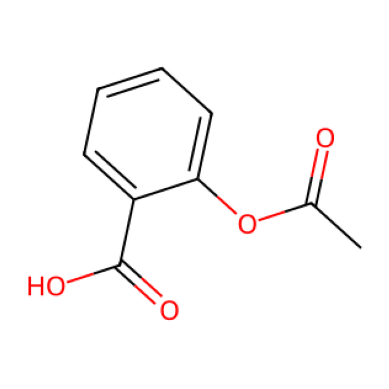

In [3]:
from rdkit import Chem
from rdkit.Chem import Descriptors, Draw
from rdkit.Chem.rdMolDescriptors import CalcMolFormula
import matplotlib.pyplot as plt

for nombre, smiles in (("aspirina", "CC(=O)OC1=CC=CC=C1C(=O)O"), ("agua", "O"), ("cafeína", "CN1C=NC2=C1C(=O)N(C(=O)N2C)C")):
    molecula = Chem.MolFromSmiles(smiles)
    print(f"{nombre:9} {CalcMolFormula(molecula):10} {Descriptors.MolWt(molecula):.3f} g/mol")
plt.imshow(Draw.MolToImage(Chem.MolFromSmiles("CC(=O)OC1=CC=CC=C1C(=O)O")))
plt.axis("off")
plt.show()

## 4. Parada de autobús con `simpy`

Simular una parada a la que llegan personas cada minuto y autobuses cada 5-10 minutos (capacidad 50). Representar el número de personas que esperan a lo largo del tiempo.

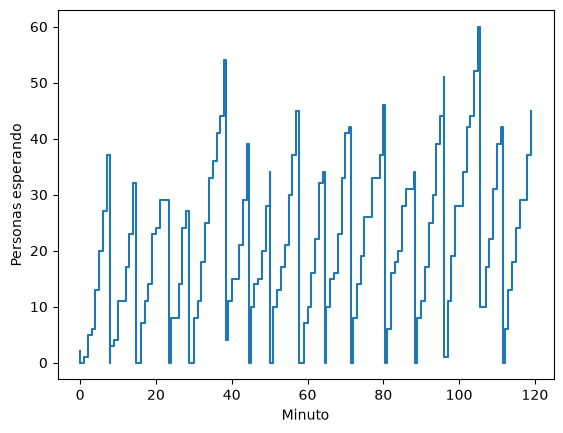

In [4]:
import random
import simpy

class Parada:
    def __init__(self, env, capacidad_bus):
        self.env, self.capacidad_bus = env, capacidad_bus
        self.personas = 0
        self.registro = []

    def anota(self):
        self.registro.append((self.env.now, self.personas))

    def llega_persona(self):
        while True:
            self.personas += random.randint(0, 10)
            self.anota()
            yield self.env.timeout(1)

    def llega_bus(self):
        while True:
            self.personas -= min(self.capacidad_bus, self.personas)
            self.anota()
            yield self.env.timeout(random.uniform(5, 10))

random.seed(1)
env = simpy.Environment()
parada = Parada(env, capacidad_bus=50)
env.process(parada.llega_persona())
env.process(parada.llega_bus())
env.run(until=120)
plt.step(*zip(*parada.registro), where="post")
plt.xlabel("Minuto")
plt.ylabel("Personas esperando")
plt.show()

## 5. Imagen en blanco y negro con `scikit-image`

Rotar la imagen de ejemplo `astronaut`, convertirla a blanco y negro y guardarla en un fichero PNG.

True


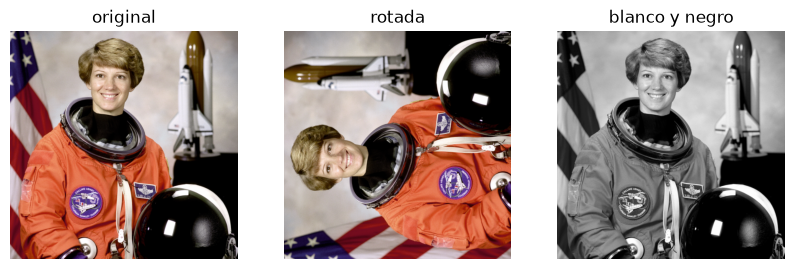

In [5]:
import os
from skimage import data, io
from skimage.color import rgb2gray
from skimage.transform import rotate
from skimage.util import img_as_ubyte

imagen = data.astronaut()
rotada = rotate(imagen, angle=90, resize=True)
gris = rgb2gray(imagen)
io.imsave("astronauta_gris.png", img_as_ubyte(gris))
fig, ax = plt.subplots(1, 3, figsize=(10, 3.5))
for eje, img, titulo in zip(ax, (imagen, rotada, gris), ("original", "rotada", "blanco y negro")):
    eje.imshow(img, cmap="gray")
    eje.set_title(titulo)
    eje.axis("off")
plt.show()
print(os.path.exists("astronauta_gris.png"))

## 6. Clave privada con un ordenador cuántico simulado (`qiskit`)

Generar una clave privada de 64 bits aleatorios poniendo 64 qubits en superposición con puertas de Hadamard y midiéndolos. El ejemplo original usaba un ordenador cuántico real de IBM (necesita una cuenta y un token); aquí se usa el simulador `qiskit-aer`.

In [6]:
from qiskit import ClassicalRegister, QuantumCircuit, QuantumRegister, transpile
from qiskit_aer import AerSimulator

q, c = QuantumRegister(64), ClassicalRegister(64)
circ = QuantumCircuit(q, c)
circ.h(q)
circ.measure(q, c)
# H y medidas son puertas de Clifford: el método stabilizer simula 64 qubits sin agotar memoria
simulador = AerSimulator(method="stabilizer")
bits = simulador.run(transpile(circ, simulador), shots=1, memory=True).result().get_memory()[0]
print(f"Clave privada: {int(bits, 2):016x}")
print(len(bits), "bits:", bits)

Clave privada: e804f3d981497a39
64 bits: 1110100000000100111100111101100110000001010010010111101000111001
